# 全臺有多少「像東北角」的場域?共同配送效益的放大估算

**為什麼做這份:** 1026 報告的三個減碳方案中,方案 A(四家共配)只算了瑞芳物流中心 7 輛車進出東北角的部分,方案 B(物流中心改插電)、C(改加 HVO)則是算 7 輛車全部的用油。三者的計算範圍不同,不能直接比大小。這份 notebook 回答兩個問題:

1. **全臺有多少門市的條件和東北角的偏遠門市相似?** 也就是自家品牌門市稀疏(車要專程繞過去)、但附近有他牌門市(有得合併)。
2. **把東北角的每店效益放大到這些門市,全臺共配可以減多少碳?** 這樣方案 A 才能和 B、C 用一致的基準比較。

**資料:**
- 四大超商門市:OpenStreetMap(`shop=convenience`,依品牌標籤與店名辨識),快取於 `poc/cache/osm_convenience_tw.json`。
- 鄉鎮市區界線:內政部國土測繪中心 1140318 版(TWD97 經緯度)。
- 每店效益:`poc/2_a_group_rebuild.ipynb` 第 7 節校準版(每趟上限 25 店)。

In [1]:
import json, math, os, re
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "poc" else os.getcwd()
P = lambda *a: os.path.join(ROOT, *a)
plt.rcParams.update({"font.family": "Microsoft JhengHei", "axes.unicode_minus": False, "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)
BRANDS = ["7-Eleven", "全家", "OK", "萊爾富"]
BCOL = {"7-Eleven": "#2a78d6", "全家": "#1baf7a", "OK": "#eb6834", "萊爾富": "#4a3aa7"}
NE4 = ["瑞芳區", "貢寮區", "雙溪區", "平溪區"]

## 1. 全臺四大超商門市(OpenStreetMap)

依 `brand`、`brand:zh`、`brand:en`、`name` 等標籤辨識品牌,再以鄉鎮界線過濾掉臺灣以外(查詢範圍含福建沿海)的點。

In [2]:
osm = json.load(open(P("poc", "cache", "osm_convenience_tw.json"), encoding="utf-8"))
PAT = {"7-Eleven": r"7[\s\-‐‑]?eleven|7[\s\-]?11|統一超商|セブン",
       "全家": r"全家|family\s?mart",
       "萊爾富": r"萊爾富|hi[\s\-]?life",
       "OK": r"^ok\b|ok\s?mart|ok便利|ok超商|ok‧|來來超商"}

def brand_of(t):
    s = " | ".join(str(t.get(k, "")) for k in ["brand", "brand:zh", "brand:en", "name", "name:zh", "name:en", "operator"]).lower()
    for b in ["7-Eleven", "全家", "萊爾富"]:
        if re.search(PAT[b], s):
            return b
    for k in ["brand", "brand:en", "name", "name:en", "name:zh"]:
        if re.search(PAT["OK"], str(t.get(k, "")).lower()):
            return "OK"
    return None

rows = []
for e in osm:
    lat, lon = (e["lat"], e["lon"]) if e["type"] == "node" else (e["center"]["lat"], e["center"]["lon"])
    rows.append({"osm_id": f"{e['type']}/{e['id']}", "lat": lat, "lon": lon, "name": e.get("tags", {}).get("name", ""),
                 "brand": brand_of(e.get("tags", {}))})
st = pd.DataFrame(rows).drop_duplicates("osm_id")

TOWN = gpd.read_file(P("鄉(鎮、市、區)界線1140318", "TOWN_MOI_1140318.shp"))
TOWN["COUNTYNAME"] = TOWN["COUNTYNAME"].str.replace("台", "臺")
TOWN["town"] = TOWN["COUNTYNAME"] + TOWN["TOWNNAME"]
TOWN["area_km2"] = TOWN.to_crs(3826).area / 1e6
g = gpd.GeoDataFrame(st, geometry=gpd.points_from_xy(st["lon"], st["lat"]), crs=TOWN.crs)
g = gpd.sjoin(g, TOWN[["COUNTYNAME", "TOWNNAME", "town", "geometry"]], how="inner", predicate="within").drop(columns="index_right")
s4 = g[g["brand"].notna()].copy()

cnt = s4["brand"].value_counts().reindex(BRANDS)
print(f"OSM 便利商店(臺灣境內)共 {len(g):,} 家;辨識為四大品牌 {len(s4):,} 家:", cnt.to_dict())
print(f"其他(未辨識品牌或非四大):{g['brand'].isna().sum():,} 家")
print("經濟部統計處:2025 年 8 月全國便利商店 14,236 家 → OSM 四大品牌涵蓋率約",
      f"{len(s4) / 14236:.0%}(分母含少數非四大品牌,實際涵蓋率略高)")

OSM 便利商店(臺灣境內)共 13,412 家;辨識為四大品牌 11,860 家: {'7-Eleven': 5963, '全家': 3641, 'OK': 530, '萊爾富': 1726}
其他(未辨識品牌或非四大):1,552 家
經濟部統計處:2025 年 8 月全國便利商店 14,236 家 → OSM 四大品牌涵蓋率約 83%(分母含少數非四大品牌,實際涵蓋率略高)


### 1.1 對照經濟部商業署「5 大超商分公司登記資料」

商業署提供統一、全家、萊爾富、OK、全聯的分公司登記資料(根目錄 `全國5大超商資料集.csv`,只有地址、沒有座標)。只取狀態 `01 核准設立`,從地址解析出縣市與鄉鎮,和 OSM 逐鄉鎮比對家數。

In [3]:
reg = pd.read_csv(P("全國5大超商資料集.csv"), dtype=str, encoding="utf-8-sig")
reg["brand"] = reg["公司統一編號"].map({"22555003": "7-Eleven", "23060248": "全家", "23285582": "萊爾富", "22853565": "OK", "16740494": "全聯"})
print("分公司狀態(01 核准設立、02 停業、03 廢止、06 撤銷):")
display(pd.crosstab(reg["brand"], reg["分公司狀態"], margins=True, margins_name="合計"))
reg = reg[(reg["分公司狀態"] == "01") & reg["brand"].isin(BRANDS)].copy()
addr = reg["分公司地址"].str.replace("台", "臺").str.replace(r"\s", "", regex=True)
m_ = addr.str.extract(r"^(\D{2}[縣市])(\D{1,4}?[鄉鎮市區])")
reg["COUNTYNAME"], reg["TOWNNAME"] = m_[0], m_[1]
reg["town"] = reg["COUNTYNAME"] + reg["TOWNNAME"]
ok_town = reg["town"].isin(TOWN["town"])
print(f"地址可解析到鄉鎮:{ok_town.mean():.1%}(其餘多為新竹市、嘉義市等地址未寫區名)")
tot = pd.DataFrame({"經濟部登記(01 核准設立)": reg["brand"].value_counts(), "OSM": s4["brand"].value_counts()}).reindex(BRANDS)
tot["OSM ÷ 登記"] = (tot["OSM"] / tot["經濟部登記(01 核准設立)"]).map("{:.0%}".format)
display(tot)

分公司狀態(01 核准設立、02 停業、03 廢止、06 撤銷):


分公司狀態,01,03,06,合計
brand,,,,
7-Eleven,7048,3443,2,10493
OK,229,1511,0,1740
全家,3600,2312,3,5915
全聯,1312,241,0,1553
萊爾富,1523,1542,0,3065
合計,13712,9049,5,22766


地址可解析到鄉鎮:97.0%(其餘多為新竹市、嘉義市等地址未寫區名)


,經濟部登記(01 核准設立),OSM,OSM ÷ 登記
brand,,,
7-Eleven,7048,5963,85%
全家,3600,3641,101%
OK,229,530,231%
萊爾富,1523,1726,113%


**判讀:** 7-Eleven 登記 7,048 家、萊爾富 1,523 家,與兩家公司公布的門市規模相當,可以視為完整名單;全家 3,600 家、OK 229 家明顯偏少,推測加盟店另以獨立商號登記,不在分公司名單內。東北角四區的登記家數與實地核對結果一致(7-Eleven 17 家、OK 4 家、萊爾富 2 家),全家少 2 家。

因此本 notebook **以 OSM 的座標為主**(登記資料沒有座標),**用 7-Eleven 與萊爾富的登記家數檢查 OSM 在各鄉鎮的漏標程度**。

In [4]:
cmp = (reg[ok_town & reg["brand"].isin(["7-Eleven", "萊爾富"])].groupby(["town", "brand"]).size().rename("登記")
       .to_frame().join(s4[s4["brand"].isin(["7-Eleven", "萊爾富"])].groupby(["town", "brand"]).size().rename("OSM"), how="outer")
       .fillna(0).reset_index())
cmp = cmp.merge(TOWN[["town", "area_km2"]], on="town")
cmp["密度分組"] = pd.cut(cmp["登記"] / cmp["area_km2"], [0, 0.1, 0.5, 2, 1e9], labels=["< 0.1 家/km²(偏遠)", "0.1–0.5", "0.5–2", "> 2(都市)"])
cv = cmp.groupby(["brand", "密度分組"], observed=True)[["登記", "OSM"]].sum()
cv["OSM ÷ 登記"] = (cv["OSM"] / cv["登記"]).map("{:.0%}".format)
display(cv)

登記     OSM OSM ÷ 登記
brand    密度分組                                    
7-Eleven < 0.1 家/km²(偏遠)   483.0   472.0      98%
         0.1–0.5          1439.0  1291.0      90%
         0.5–2            2245.0  1916.0      85%
         > 2(都市)          2635.0  2161.0      82%
萊爾富      < 0.1 家/km²(偏遠)   301.0   371.0     123%
         0.1–0.5           611.0   702.0     115%
         0.5–2             423.0   484.0     114%
         > 2(都市)           141.0   112.0      79%

**涵蓋率的意義:** OSM 由志工標註,都市區漏標較多(7-Eleven 只有約 8 成),但**偏遠鄉鎮的涵蓋率很高**(門市密度 < 0.1 家/km² 的鄉鎮,7-Eleven 達 98%)。下面判定的是偏遠門市,受漏標影響較小。萊爾富與 OK 的 OSM 家數比登記多,可能含已歇業但未更新的點,或登記資料不完整。

## 2. 用東北角定出「偏遠門市」的條件

校準版的結論是:共配的效益集中在**離自家其他門市很遠、車要專程繞過去**的門市(貢寮、雙溪)。一開始我們用「離最近的同品牌門市多遠」判斷,但分不出來:福隆、澳底的幾家 7-Eleven 彼此很近(中位數約 0.3 km),問題在**這一小群門市整體離自家路網很遠**。

一趟車大約送 20 家店,所以改看**離第 5 近的同品牌門市多遠**(`d5`):要開多遠才湊得到 5 家自家門市。另外看**離最近的他牌門市多遠**(`d_other`),判斷有沒有得合併。直線距離,公里:

In [5]:
xy = np.c_[s4["lon"].values * 101.0 * math.cos(math.radians(23.7)), s4["lat"].values * 111.0]   # 近似 km 座標
K = 5
s4["d5"] = np.nan; s4["d_other"] = np.nan
for b in BRANDS:
    m = (s4["brand"] == b).values
    s4.loc[m, "d5"] = cKDTree(xy[m]).query(xy[m], k=K + 1)[0][:, K]
    s4.loc[m, "d_other"] = cKDTree(xy[~m]).query(xy[m], k=1)[0]

ne = s4[(s4["COUNTYNAME"] == "新北市") & s4["TOWNNAME"].isin(NE4)].copy()
ne["型態"] = np.where(ne["TOWNNAME"].isin(["貢寮區", "雙溪區"]), "貢寮、雙溪(專程)", np.where(ne["TOWNNAME"] == "平溪區", "平溪(早班幹線回程)", "瑞芳區(晚班幹線前段)"))
display(ne.groupby("型態")[["d5", "d_other"]].agg(["min", "median", "max"]).round(1))
print("東北角四區 OSM 四大品牌門市:", ne["brand"].value_counts().reindex(BRANDS).to_dict(), f"合計 {len(ne)} 家(實地核對後為 33 家)")
print("全臺 d5 分位數(km):", s4["d5"].quantile([.5, .8, .9, .95, .98]).round(1).to_dict())

d5              d_other            
             min median   max     min median  max
型態                                               
平溪(早班幹線回程)   7.3    7.6   7.6     0.1    0.1  4.5
瑞芳區(晚班幹線前段)  1.7    2.9   8.6     0.0    0.2  4.9
貢寮、雙溪(專程)    5.4    7.7  15.0     0.0    0.1  6.0

東北角四區 OSM 四大品牌門市: {'7-Eleven': 18, '全家': 9, 'OK': 6, '萊爾富': 2} 合計 35 家(實地核對後為 33 家)
全臺 d5 分位數(km): {0.5: 0.9, 0.8: 2.3, 0.9: 4.0, 0.95: 6.3, 0.98: 10.3}


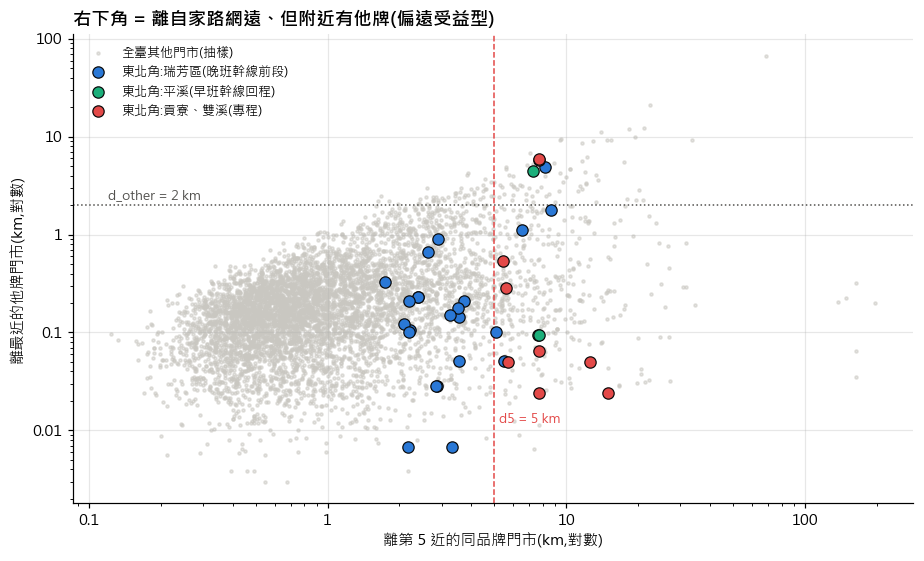

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
oth = s4.sample(min(len(s4), 6000), random_state=1)
ax.scatter(oth["d5"], oth["d_other"], s=4, color="#c9c7c1", alpha=0.5, label="全臺其他門市(抽樣)")
for k_, col in [("瑞芳區(晚班幹線前段)", "#2a78d6"), ("平溪(早班幹線回程)", "#1baf7a"), ("貢寮、雙溪(專程)", "#e34948")]:
    d = ne[ne["型態"] == k_]
    ax.scatter(d["d5"], d["d_other"], s=55, color=col, edgecolor="#0b0b0b", linewidth=0.8, label=f"東北角:{k_}", zorder=3)
ax.axvline(5, color="#e34948", ls="--", lw=1); ax.axhline(2, color="#52514e", ls=":", lw=1)
ax.text(5.2, 0.012, "d5 = 5 km", color="#e34948", fontsize=8.5); ax.text(0.12, 2.3, "d_other = 2 km", color="#52514e", fontsize=8.5)
ax.set_xscale("log"); ax.set_yscale("log")
from matplotlib.ticker import FuncFormatter
for a_ in (ax.xaxis, ax.yaxis):
    a_.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel("離第 5 近的同品牌門市(km,對數)"); ax.set_ylabel("離最近的他牌門市(km,對數)")
ax.legend(fontsize=8.5, frameon=False, loc="upper left")
ax.set_title("右下角 = 離自家路網遠、但附近有他牌(偏遠受益型)", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

**條件:**

- **偏遠:** `d5 ≥ 5 km`。東北角的貢寮、雙溪門市全部 ≥ 5.4 km;瑞芳區大多 1.7–3.7 km。全臺約 9 成門市 < 4 km。
- **有得合併:** `d_other ≤ 2 km`,2 公里內有他牌門市。
- 兩者都成立,稱為**偏遠受益型門市**。

**限制:** 「偏遠」不等於「專程配送」。平溪的 `d5` 約 7.5 km,也符合偏遠條件,但它在全家早班幹線的回程上,校準版中共配幾乎省不到;瑞芳區也有少數門市符合條件。所以第 4 節放大時,不直接套用貢寮的每店效益,而是用**東北角所有符合條件的門市平均**,把這類順路情形一起算進去。

In [7]:
D5_MIN, D_OTHER_MAX = 5.0, 2.0
s4["偏遠"] = s4["d5"] >= D5_MIN
s4["偏遠受益型"] = s4["偏遠"] & (s4["d_other"] <= D_OTHER_MAX)
ne = ne.drop(columns=[c for c in ["偏遠", "偏遠受益型"] if c in ne]).merge(s4[["osm_id", "偏遠", "偏遠受益型"]], on="osm_id")
print("條件在東北角的判定結果:")
display(pd.crosstab(ne["型態"], ne["偏遠受益型"].map({True: "偏遠受益型", False: "其他"})))
n_r = int(s4["偏遠受益型"].sum())
print(f"全臺偏遠門市 {int(s4['偏遠'].sum()):,} 家;其中偏遠受益型 {n_r:,} 家(占四大品牌 {n_r / len(s4):.1%});"
      f"偏遠但 2 km 內沒有他牌 {int((s4['偏遠'] & ~s4['偏遠受益型']).sum()):,} 家(無法共配)")
display(s4[s4["偏遠受益型"]]["brand"].value_counts().reindex(BRANDS).rename("偏遠受益型家數").to_frame().T)

條件在東北角的判定結果:


偏遠受益型,偏遠受益型,其他
型態,,
平溪(早班幹線回程),2,1
瑞芳區(晚班幹線前段),4,19
貢寮、雙溪(專程),7,2


全臺偏遠門市 874 家;其中偏遠受益型 717 家(占四大品牌 6.0%);偏遠但 2 km 內沒有他牌 157 家(無法共配)


brand,7-Eleven,全家,OK,萊爾富
偏遠受益型家數,193,215,121,188


## 3. 這些門市在哪裡

依鄉鎮彙總。**類似東北角的場域**定義為:鄉鎮內至少有 2 家偏遠受益型門市,且來自至少 2 個品牌(才有跨品牌合併的空間)。離島(澎湖、金門、連江)物流型態不同(海運、在地倉),另外列出。

In [8]:
ISL = ["澎湖縣", "金門縣", "連江縣"]
tw = (s4.groupby(["COUNTYNAME", "TOWNNAME", "town"])
        .agg(四大門市=("osm_id", "size"), 偏遠受益型=("偏遠受益型", "sum"),
             偏遠受益型品牌數=("brand", lambda s: s[s4.loc[s.index, "偏遠受益型"]].nunique()))
        .reset_index().merge(TOWN[["town", "area_km2"]], on="town"))
tw = tw.merge(reg[ok_town].groupby("town").size().rename("經濟部登記(四品牌)").reset_index(), on="town", how="left").fillna({"經濟部登記(四品牌)": 0})
tw["門市密度(家/km²)"] = tw["四大門市"] / tw["area_km2"]
tw["離島"] = tw["COUNTYNAME"].isin(ISL)
tw["類似東北角"] = (tw["偏遠受益型"] >= 2) & (tw["偏遠受益型品牌數"] >= 2)
like = tw[tw["類似東北角"]].sort_values("偏遠受益型", ascending=False)
print(f"類似東北角的鄉鎮:{len(like)} 個(本島 {int((~like['離島']).sum())}、離島 {int(like['離島'].sum())});"
      f"其中的偏遠受益型門市 {int(like['偏遠受益型'].sum()):,} 家")
display(like.groupby(["離島", "COUNTYNAME"]).agg(鄉鎮數=("town", "size"), 偏遠受益型門市=("偏遠受益型", "sum"))
            .sort_values("偏遠受益型門市", ascending=False))
like.head(30)[["COUNTYNAME", "TOWNNAME", "四大門市", "經濟部登記(四品牌)", "偏遠受益型", "偏遠受益型品牌數", "area_km2"]].round(1)

類似東北角的鄉鎮:153 個(本島 147、離島 6);其中的偏遠受益型門市 604 家


鄉鎮數  偏遠受益型門市
離島    COUNTYNAME              
False 屏東縣          17       62
      南投縣          10       58
      雲林縣          14       58
      宜蘭縣          10       47
      苗栗縣          11       47
      臺南市          12       46
      新北市          12       44
      嘉義縣           9       44
      高雄市          12       35
      臺東縣          10       31
      彰化縣           9       30
      花蓮縣           6       25
      桃園市           5       24
      臺中市           5       19
      新竹縣           5       19
True  金門縣           3        9
      澎湖縣           3        6

,COUNTYNAME,TOWNNAME,四大門市,經濟部登記(四品牌),偏遠受益型,偏遠受益型品牌數,area_km2
50,宜蘭縣,蘇澳鎮,22,26.0,13,4,89.6
326,雲林縣,麥寮鄉,17,15.0,11,3,125.4
1,南投縣,仁愛鄉,10,8.0,10,3,1220.3
60,屏東縣,恆春鎮,28,25.0,10,3,141.0
281,苗栗縣,三義鄉,10,8.0,9,4,67.7
135,新北市,金山區,9,7.0,9,3,47.7
4,南投縣,名間鄉,12,11.0,8,4,79.3
153,新竹縣,關西鎮,12,6.0,8,4,125.2
51,宜蘭縣,頭城鎮,17,13.0,8,3,102.5
293,苗栗縣,通霄鎮,10,12.0,8,3,113.8


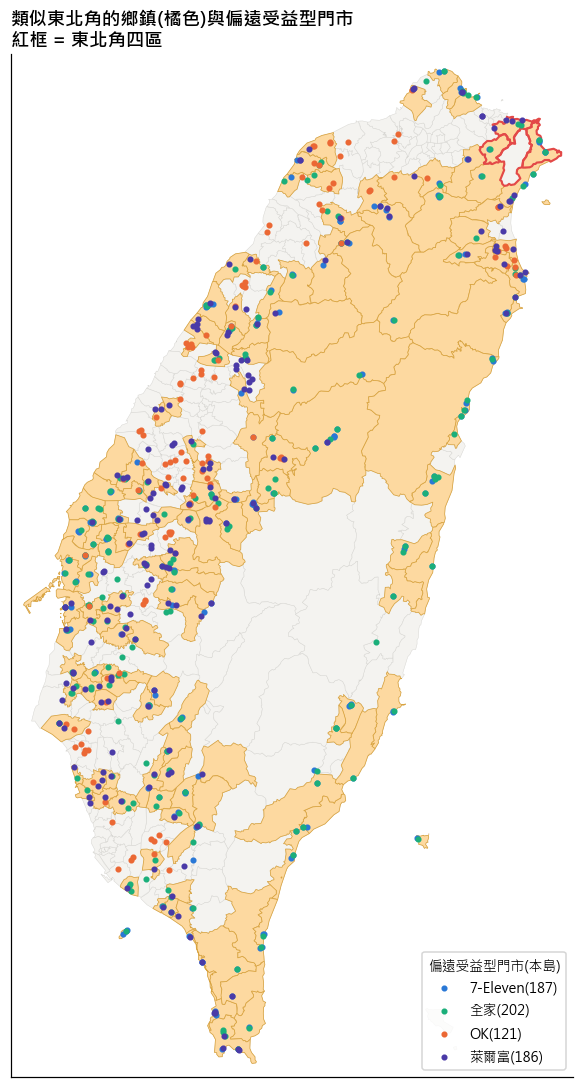

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 10))
main = TOWN[~TOWN["COUNTYNAME"].isin(ISL)].copy()
main["geometry"] = main.geometry.simplify(0.002)
main = main.merge(tw[["town", "類似東北角"]], on="town", how="left")
main.plot(ax=ax, color="#f4f3f0", edgecolor="#d6d5d1", linewidth=0.3)
main[main["類似東北角"] == True].plot(ax=ax, color="#fdd9a0", edgecolor="#d9a441", linewidth=0.5)
main[(main["COUNTYNAME"] == "新北市") & main["TOWNNAME"].isin(NE4)].boundary.plot(ax=ax, color="#e34948", linewidth=1.4)
r = s4[s4["偏遠受益型"] & ~s4["COUNTYNAME"].isin(ISL)]
for b in BRANDS:
    d = r[r["brand"] == b]
    ax.scatter(d["lon"], d["lat"], s=9, color=BCOL[b], label=f"{b}({len(d)})", zorder=3)
ax.set_xlim(119.95, 122.05); ax.set_ylim(21.85, 25.35); ax.set_aspect(1 / math.cos(math.radians(23.7)))
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.legend(title="偏遠受益型門市(本島)", fontsize=9, title_fontsize=9, loc="lower right", frameon=True)
ax.set_title("類似東北角的鄉鎮(橘色)與偏遠受益型門市\n紅框 = 東北角四區", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 4. 放大估算:全臺偏遠門市共配可以減多少碳

用校準版(每趟上限 25 店)換算「**每家偏遠受益型門市**每輪能省多少」:

- **中估:** 東北角 R1 共省 75.0 km,除以東北角被判為偏遠受益型的門市數。這個平均已包含平溪、瑞芳少數門市「雖偏遠但順路、省不到」的情形。
- **高估:** 每家都像貢寮、雙溪一樣是專程配送:69.2 km ÷ 8 家 = 8.65 km。
- **低估:** 偏遠門市不由同一個物流中心配送(R2),只剩瑞芳、平溪的 5.8 km,同樣除以東北角偏遠受益型門市數。

全臺 = 偏遠受益型門市數 × 每店每輪少跑 km × 每日一輪 × 365 天 × 0.551 kg CO₂/km。**只算偏遠門市**:都市與一般鄉鎮的門市密集,共配效益要另外建模,東北角的數字不能外推。

In [10]:
KG_PER_KM = 0.212 * 2.60
def t_year(km_day):
    return km_day * KG_PER_KM * 365 / 1000
n_ne = int(ne["偏遠受益型"].sum())
PER = {"低估(R2)": 5.8 / n_ne, "中估(R1,東北角平均)": 75.0 / n_ne, "高估(全部專程)": 69.2 / 8}
n_main = int((s4["偏遠受益型"] & ~s4["COUNTYNAME"].isin(ISL)).sum())
n_all = int(s4["偏遠受益型"].sum())
print(f"東北角偏遠受益型門市 {n_ne} 家 → 每店每輪少跑:" + "、".join(f"{k} {v:.2f} km" for k, v in PER.items()))
est = pd.DataFrame([{"情境": k, "每店每輪少跑 km": v,
                     "本島:每年減碳(公噸)": t_year(n_main * v), "含離島:每年減碳(公噸)": t_year(n_all * v)} for k, v in PER.items()])
display(est.round(1))
print(f"(本島偏遠受益型門市 {n_main} 家,含離島 {n_all} 家;每日一輪為示意假設)")

東北角偏遠受益型門市 13 家 → 每店每輪少跑:低估(R2) 0.45 km、中估(R1,東北角平均) 5.77 km、高估(全部專程) 8.65 km


,情境,每店每輪少跑 km,本島:每年減碳(公噸),含離島:每年減碳(公噸)
0,低估(R2),0.4,62.5,64.4
1,"中估(R1,東北角平均)",5.8,807.8,832.2
2,高估(全部專程),8.6,1211.2,1247.8


(本島偏遠受益型門市 696 家,含離島 717 家;每日一輪為示意假設)


In [11]:
# 敏感度:偏遠門檻 d5 改變時,門市數與中估減碳量怎麼變
sens = []
for d5 in [4, 5, 6, 8, 10]:
    f_all = (s4["d5"] >= d5) & (s4["d_other"] <= D_OTHER_MAX)
    f_ne = f_all[s4["osm_id"].isin(ne["osm_id"])].sum()
    per = 75.0 / f_ne if f_ne else np.nan
    sens.append({"d5 門檻(km)": d5, "全臺偏遠受益型門市": int(f_all.sum()), "東北角符合家數": int(f_ne),
                 "中估每店每輪少跑 km": per, "中估每年減碳(公噸,含離島)": t_year(int(f_all.sum()) * per)})
pd.DataFrame(sens).round(1)

,d5 門檻(km),全臺偏遠受益型門市,東北角符合家數,中估每店每輪少跑 km,"中估每年減碳(公噸,含離島)"
0,4,1003,13,5.8,1164.2
1,5,717,13,5.8,832.2
2,6,514,8,9.4,969.5
3,8,298,3,25.0,1498.9
4,10,192,2,37.5,1448.6


## 5. 三個方案放到同一個基準

1026 報告的方案 B(物流中心改插電,每年 11–17 公噸)與方案 C(改加 HVO,每年 288 公噸)只算瑞芳物流中心 **7 輛**有油耗資料的車。要和全臺的方案 A 比較,需要把 B、C 也放大到全臺。全臺超商配送車隊沒有公開數字,這裡用**瑞芳物流中心每輛車服務的門市數**換算:

全臺車數 ≈ 全臺門市數 ÷ 瑞芳每車服務門市數(假設各品牌、各物流中心的車隊效率與瑞芳相近)。

**要注意:** 這是「同一種車隊、同樣效率」的換算。瑞芳資料的車都是 5t 冷凍車廂車,TMS 車廂溫度中位數約 17°C(鮮食溫層);全臺實際的超商配送車隊還包括常溫、冷凍等其他溫層與各品牌的物流體系,車數會更多。方案 A 的共配效益也是用同一批車的路線算出來的,所以三個方案在這個換算下基準一致,但絕對數字只能當數量級參考。

In [12]:
import glob
mp = pd.concat([pd.read_csv(f, dtype=str, encoding="utf-8-sig") for f in glob.glob(P("delivery_plan", "monthly", "*.csv"))])
rf_stores = mp.loc[mp["Store_id"].str.startswith("1001", na=False), "Store_id"].nunique()
vcl = pd.read_csv(P("vehicle_class_by_V.csv"), encoding="utf-8-sig")
rf_veh = int((vcl["在車輛總表"] == "是").sum())
per_veh = rf_stores / rf_veh
n_store_tw = 14236
veh_tw = n_store_tw / per_veh
print(f"瑞芳物流中心:門市 {rf_stores} 家、總表車輛 {rf_veh} 輛 → 每車約 {per_veh:.0f} 家")
print(f"全臺便利商店 {n_store_tw:,} 家(經濟部統計處 2025-08)→ 換算約 {veh_tw:,.0f} 輛車(示意)")
B7, C7 = (11, 17), 288
cmp3 = pd.DataFrame([
    {"方案": "A 四家共配(只限偏遠門市)", "1026 報告(7 輛車)": "約 0.04–0.23", "全臺(示意)": f"{est.iloc[0]['含離島:每年減碳(公噸)']:,.0f}–{est.iloc[2]['含離島:每年減碳(公噸)']:,.0f}(中估 {est.iloc[1]['含離島:每年減碳(公噸)']:,.0f})",
     "放大依據": "偏遠受益型門市數"},
    {"方案": "B 物流中心改插電", "1026 報告(7 輛車)": "11–17", "全臺(示意)": f"{B7[0] / 7 * veh_tw:,.0f}–{B7[1] / 7 * veh_tw:,.0f}", "放大依據": "車輛數"},
    {"方案": "C 改加 HVO", "1026 報告(7 輛車)": "288", "全臺(示意)": f"{C7 / 7 * veh_tw:,.0f}", "放大依據": "車輛數"},
])
cmp3

瑞芳物流中心:門市 806 家、總表車輛 17 輛 → 每車約 47 家
全臺便利商店 14,236 家(經濟部統計處 2025-08)→ 換算約 300 輛車(示意)


,方案,1026 報告(7 輛車),全臺(示意),放大依據
0,A 四家共配(只限偏遠門市),約 0.04–0.23,"64–1,248(中估 832)",偏遠受益型門市數
1,B 物流中心改插電,11–17,472–729,車輛數
2,C 改加 HVO,288,"12,354",車輛數


## 6. 結論與對報告的影響

_(以下依本次執行結果撰寫;更改門檻或重抓 OSM 後請一併檢查數字。)_

### 主要發現

1. **全臺約有 700 家「像貢寮、雙溪」的門市。** 以 `d5 ≥ 5 km`(離第 5 近的自家門市 5 公里以上)且 2 公里內有他牌為條件,全臺四大超商有 **717 家**偏遠受益型門市,占 6%;分布在 **153 個鄉鎮**(本島 147、離島 6),以屏東、南投、雲林、宜蘭、苗栗最多。門檻改成 4–6 km 時為 514–1,003 家。
2. **小品牌最需要共配。** 偏遠受益型門市占各品牌門市的比例:OK 約 23%、萊爾富約 11%、全家約 6%、7-Eleven 約 3%。門市越少的品牌,在鄉間越常「為了一兩家店專程跑一趟」,參與共配的誘因越大;7-Eleven 路網最密,誘因最小。這也是推動共配時要面對的協調問題。
3. **放大到全臺,共配每年約可減 830 公噸 CO₂(範圍 64–1,250 公噸)。** 中估用東北角的平均每店效益(每店每輪 5.8 km),已包含平溪這類「偏遠但順路」的門市;低估假設偏遠門市不由同一物流中心配送,高估假設全部是專程配送。門檻改成 4–6 km 時,中估為 830–1,160 公噸。
4. **用同一個基準比,方案 A 不再是「幾乎沒效果」。** 1026 報告中方案 A 只有 0.04–0.23 公噸,是因為只算 7 輛車、而這 7 輛車很少進東北角。以「瑞芳每車服務約 47 家門市」把三個方案都換算到全臺(約 300 輛同類車,示意):
   - A 四家共配:約 830 公噸(64–1,250)
   - B 物流中心改插電:約 470–730 公噸
   - C 改加 HVO:約 12,000 公噸
   - 方案 A 與 B 落在同一個數量級;C 仍最大,但成本也最高(1026 報告第 21 頁)。

### 回答「共配的減碳效益是否受納入的商店數量與場域數量影響」

**會,而且兩者的放大方式不同。**
- 方案 A 的效益取決於**偏遠受益型門市有多少**:都市和已在幹線上的門市,共配幾乎省不到,所以 A 的上限大約就是這 700 家門市能省的量。
- 方案 B、C 的效益則和**車輛數**成正比,車越多越多。

所以三個方案要放在同一個範圍(例如全臺,或同一批車)才能比較;只用 7 輛車比,會嚴重低估 A。

### 限制

1. **距離是直線距離:** 沒有用道路距離,山區門市的實際繞路更長。
2. **OSM 會漏標:** 都市約漏 2 成;偏遠鄉鎮涵蓋率約 98%,影響較小。
3. **每店效益只來自東北角一個案例:** 其他地區的物流中心位置、幹線走向不同。
4. **「每日一輪」與「300 輛車」都是示意假設:** 實際配送頻次與全臺車隊數仍需查證。
5. **判定只看門市分布:** 不知道各品牌物流中心在哪裡,也不知道實際路線是否順路經過。